# **Predicción de Diabetes con Redes Neuronales**

**Curso:** Agentes Inteligentes

**Integrantes (Grupo 04)**
- Alondra Yamileth Gonzales Cuaresma — 2312461
- Yasmin Akemi Haji Taira — 2310089
- Ashley Misae Kuniyoshi Zambrano — 2311528

## 1. Importaciones

In [1]:
import os, time, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, roc_auc_score, f1_score)
from tensorflow import keras; from tensorflow.keras import layers
import joblib, tensorflow as tf
keras.utils.set_random_seed(42)
print('TF:', tf.__version__)

TF: 2.22.0-rc0


**Interpretación:** El entorno quedó listo. Se cargó TensorFlow junto con las librerías de datos y de scikit-learn que se usan en todo el notebook.

## 2. Carga y preprocesamiento

In [2]:
df = pd.read_csv('diabetes_data_es_GOLD.csv')
print(df.shape)  # (520, 17)
print(df['TieneDiabetes'].value_counts())

le = LabelEncoder()
df['target'] = le.fit_transform(df['TieneDiabetes'])
print(le.classes_)  # ['Negativo' 'Positivo']

X = df.drop(columns=['TieneDiabetes','target']).values  # (520, 16)
y = df['target'].values
feature_names = list(df.drop(columns=['TieneDiabetes','target']).columns)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)
joblib.dump(scaler, 'scaler.pkl')
print(f'Train: {X_train.shape} | Test: {X_test.shape}')

(520, 17)
TieneDiabetes
Positivo    320
Negativo    200
Name: count, dtype: int64
['Negativo' 'Positivo']
Train: (416, 16) | Test: (104, 16)


**Interpretación:** El dataset tiene 520 pacientes y 17 columnas. La clase está algo desbalanceada, con más casos positivos que negativos. Tras la división estratificada quedan 416 pacientes para entrenar y 104 para probar, manteniendo la misma proporción de clases.

## 3. Correlación y exploración

,count,mean,std,min,25%,50%,75%,max
Edad,520.0,48.029,12.151,16.0,39.0,47.5,57.0,90.0
Genero,520.0,0.631,0.483,0.0,0.0,1.0,1.0,1.0
Poliuria,520.0,0.496,0.500,0.0,0.0,0.0,1.0,1.0
Polidipsia,520.0,0.448,0.498,0.0,0.0,0.0,1.0,1.0
Perdida_repentina_peso,520.0,0.417,0.494,0.0,0.0,0.0,1.0,1.0
Debilidad,520.0,0.587,0.493,0.0,0.0,1.0,1.0,1.0
Polifagia,520.0,0.456,0.499,0.0,0.0,0.0,1.0,1.0
Candidiasis_genital,520.0,0.223,0.417,0.0,0.0,0.0,0.0,1.0
Vision_borrosa,520.0,0.448,0.498,0.0,0.0,0.0,1.0,1.0
Picazon,520.0,0.487,0.500,0.0,0.0,0.0,1.0,1.0


target                    1.000000
Poliuria                  0.665922
Polidipsia                0.648734
Perdida_repentina_peso    0.436568
Paresia_parcial           0.432288
Polifagia                 0.342504
Irritabilidad             0.299467
Vision_borrosa            0.251300
Debilidad                 0.243275
Rigidez_muscular          0.122474
Candidiasis_genital       0.110288
Edad                      0.108679
Obesidad                  0.072173
Cicatrizacion_lenta       0.046980
Picazon                  -0.013384
Alopecia                 -0.267512
Genero                   -0.449233
Name: target, dtype: float64


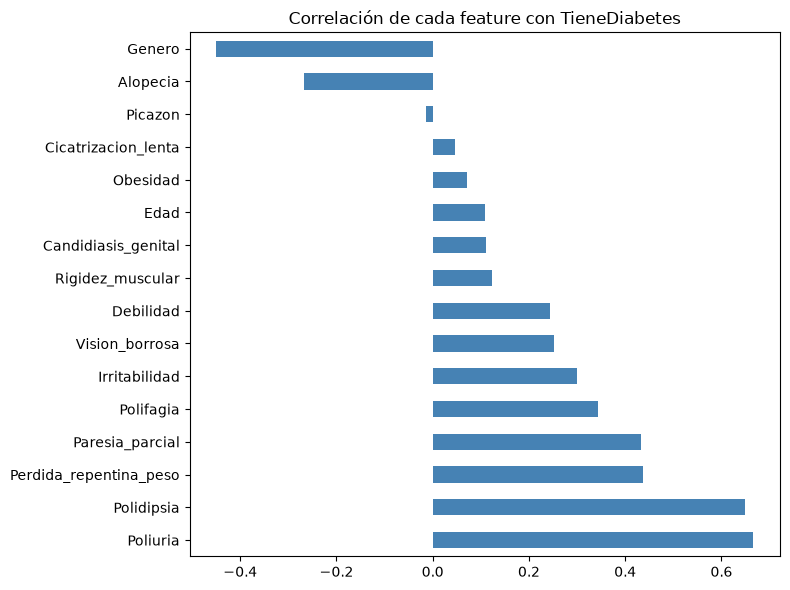

In [3]:
# Estadísticas descriptivas (equivalente al nodo Statistics de KNIME)
display(df.drop(columns=['target']).describe().T.round(3))

# Correlación con el target (equivalente al Linear Correlation de KNIME)
corr = df.drop(columns=['TieneDiabetes']).corr()['target'].sort_values(ascending=False)
print(corr)

plt.figure(figsize=(8,6))
corr.drop('target').plot(kind='barh', color='steelblue')
plt.title('Correlación de cada feature con TieneDiabetes')
plt.tight_layout(); plt.savefig('correlacion.png', dpi=150); plt.show()
# Captura requerida

**Interpretación:** Las variables más asociadas a la diabetes son Poliuria y Polidipsia, con correlaciones cercanas a 0.65, lo que coincide con los síntomas clásicos. El Género presenta la correlación negativa más fuerte y la mayoría de los síntomas aporta una señal baja o media.

## 4. Arquitectura RNA

In [4]:
# Arquitectura: [16] → [32] → [16] → [1]
model = keras.Sequential([
    keras.Input(shape=(16,)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
], name='RNA_Diabetes')
model.summary()

Model: "RNA_Diabetes"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,089 (4.25 KB)

 Trainable params: 1,089 (4.25 KB)

 Non-trainable params: 0 (0.00 B)

**Interpretación:** La red es un perceptrón multicapa con dos capas ocultas de 32 y 16 neuronas y una salida sigmoide. Suma 1089 parámetros entrenables. Las capas de dropout reducen el sobreajuste.

## 5. Entrenamiento y curva de aprendizaje

Epochs ejecutados: 100


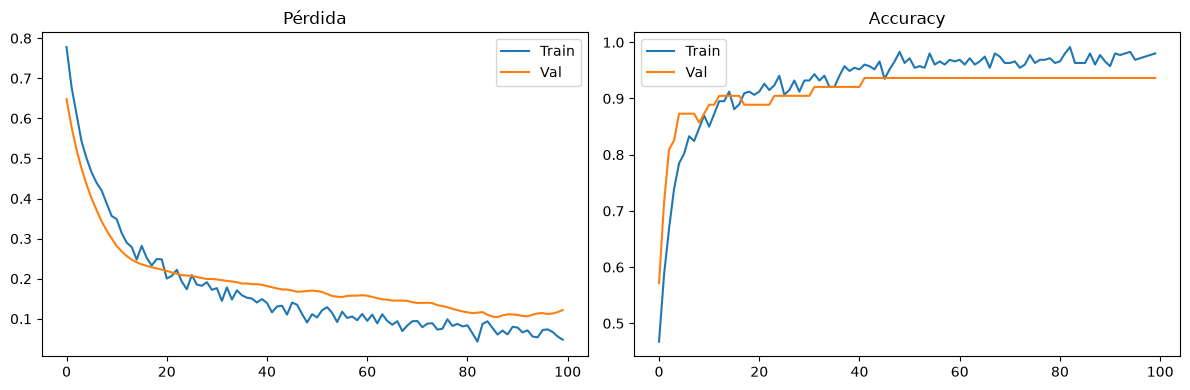

In [5]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=15, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=100, batch_size=32,
                    validation_split=0.15, callbacks=[early_stop], verbose=0)
print('Epochs ejecutados:', len(history.history['loss']))
model.save('modelo_rna.keras')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4))
ax1.plot(history.history['loss'], label='Train')
ax1.plot(history.history['val_loss'], label='Val')
ax1.set_title('Pérdida'); ax1.legend()
ax2.plot(history.history['accuracy'], label='Train')
ax2.plot(history.history['val_accuracy'], label='Val')
ax2.set_title('Accuracy'); ax2.legend()
plt.tight_layout(); plt.savefig('curva_aprendizaje.png', dpi=150); plt.show()
# Captura requerida

**Interpretación:** El modelo entrenó durante 100 épocas. En la curva, la pérdida de entrenamiento y validación bajan de forma pareja y la exactitud sube de manera estable, sin una separación grande entre ambas, lo que indica que no hay un sobreajuste marcado.

## 6. Comparación: RNA vs. Gradient Boosted Trees

In [6]:
# ── RNA ──
y_prob_rna = model.predict(X_test, verbose=0).flatten()
y_pred_rna = (y_prob_rna >= 0.5).astype(int)
acc_rna = accuracy_score(y_test, y_pred_rna)
f1_rna  = f1_score(y_test, y_pred_rna)
auc_rna = roc_auc_score(y_test, y_prob_rna)

# ── Gradient Boosted Trees ──
gbt = GradientBoostingClassifier(n_estimators=100, max_depth=5,
                                 learning_rate=0.1, random_state=42)
gbt.fit(X_train, y_train)
y_pred_gbt = gbt.predict(X_test)
y_prob_gbt = gbt.predict_proba(X_test)[:,1]
acc_gbt = accuracy_score(y_test, y_pred_gbt)
f1_gbt  = f1_score(y_test, y_pred_gbt)
auc_gbt = roc_auc_score(y_test, y_prob_gbt)

print(f"{'Modelo':<34} {'Accuracy':>10} {'F1':>8} {'AUC':>8}")
print('-'*62)
print(f"{'RNA (Keras) [32,16]':<34} {acc_rna:>10.4f} {f1_rna:>8.4f} {auc_rna:>8.4f}")
print(f"{'Gradient Boosted Trees':<34} {acc_gbt:>10.4f} {f1_gbt:>8.4f} {auc_gbt:>8.4f}")
print()
print('Reporte RNA:'); print(classification_report(y_test, y_pred_rna, target_names=le.classes_))
print('Reporte GBT:'); print(classification_report(y_test, y_pred_gbt, target_names=le.classes_))
# Captura requerida

Modelo                               Accuracy       F1      AUC
--------------------------------------------------------------
RNA (Keras) [32,16]                    0.9712   0.9764   0.9984
Gradient Boosted Trees                 0.9904   0.9921   1.0000

Reporte RNA:
              precision    recall  f1-score   support

    Negativo       0.95      0.97      0.96        40
    Positivo       0.98      0.97      0.98        64

    accuracy                           0.97       104
   macro avg       0.97      0.97      0.97       104
weighted avg       0.97      0.97      0.97       104

Reporte GBT:
              precision    recall  f1-score   support

    Negativo       0.98      1.00      0.99        40
    Positivo       1.00      0.98      0.99        64

    accuracy                           0.99       104
   macro avg       0.99      0.99      0.99       104
weighted avg       0.99      0.99      0.99       104



**Interpretación:** Ambos modelos clasifican muy bien.
- La RNA llega a una exactitud cercana a 0.97.
- El GBT llega a una exactitud cercana a 0.99.
- El GBT supera a la RNA en exactitud, F1 y AUC.
- La diferencia equivale a unos pocos pacientes de prueba, por lo que es pequeña aunque consistente.

## 7. Matrices de confusión

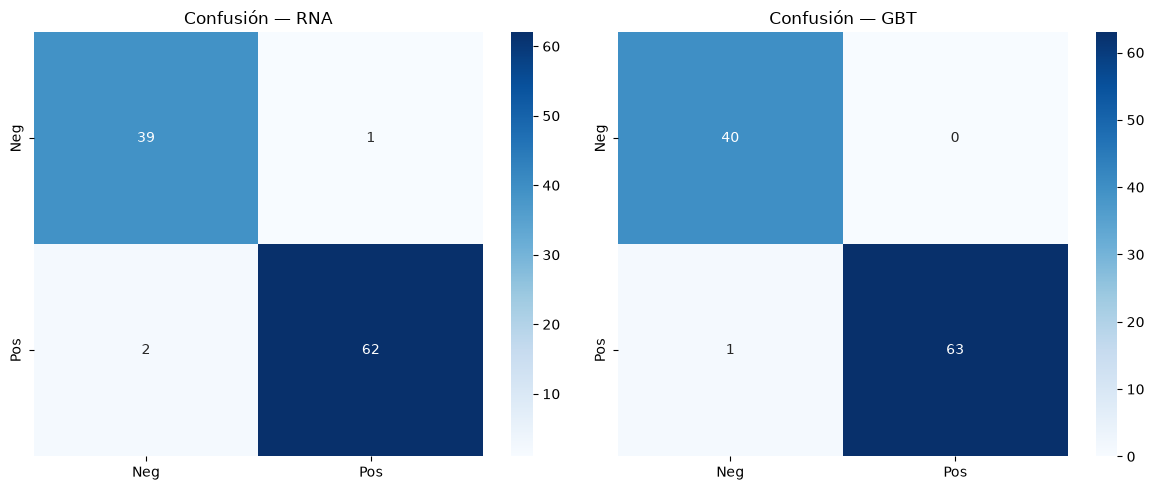

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,5))
for ax, y_pred, title in [(ax1, y_pred_rna,'RNA'),(ax2, y_pred_gbt,'GBT')]:
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Neg','Pos'], yticklabels=['Neg','Pos'])
    ax.set_title(f'Confusión — {title}')
plt.tight_layout(); plt.savefig('confusion_matrix.png', dpi=150); plt.show()
# Captura requerida

**Interpretación:** Las dos matrices muestran muy pocos errores. El GBT comete menos equivocaciones que la RNA y casi todos los pacientes positivos y negativos quedan bien clasificados.

## 8. Desafíos - funciones auxiliares
Cada experimento cambia **un solo parámetro** respecto a la base. La base de la RNA es [32,16] con partición 80/20 y semilla 42. La base del GBT es 100 árboles, profundidad 5 y learning rate 0.1.

In [8]:
def preparar(test_size=0.20, seed=42, drop_col=None):
    Xd = X if drop_col is None else np.delete(X, drop_col, axis=1)
    Xtr, Xte, ytr, yte = train_test_split(Xd, y, test_size=test_size,
                                          random_state=seed, stratify=y)
    sc = StandardScaler()
    return sc.fit_transform(Xtr), sc.transform(Xte), ytr, yte

def entrenar_rna(hidden=(32,16), test_size=0.20, seed=42, drop_col=None):
    Xtr, Xte, ytr, yte = preparar(test_size, seed, drop_col)
    keras.utils.set_random_seed(seed)
    capas = [keras.Input(shape=(Xtr.shape[1],))]
    for i, n in enumerate(hidden):
        capas += [layers.Dense(n, activation='relu'),
                  layers.Dropout(0.3 if i == 0 else 0.2)]
    capas += [layers.Dense(1, activation='sigmoid')]
    m = keras.Sequential(capas)
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(Xtr, ytr, epochs=100, batch_size=32, validation_split=0.15,
              callbacks=[es], verbose=0)
    dt = time.time() - t0
    best = int(np.argmin(h.history['val_loss']))
    prob = m.predict(Xte, verbose=0).flatten(); pred = (prob >= 0.5).astype(int)
    return dict(train_acc=h.history['accuracy'][best], val_acc=h.history['val_accuracy'][best],
                test_acc=accuracy_score(yte, pred), f1=f1_score(yte, pred),
                auc=roc_auc_score(yte, prob), epochs=best+1, ran=len(h.history['loss']),
                seg=dt, n_test=len(yte), hist=h.history)

def entrenar_gbt(n_estimators=100, lr=0.1, seed=42, test_size=0.20, drop_col=None):
    Xtr, Xte, ytr, yte = preparar(test_size, seed, drop_col)
    g = GradientBoostingClassifier(n_estimators=n_estimators, max_depth=5,
                                   learning_rate=lr, random_state=seed)
    t0 = time.time(); g.fit(Xtr, ytr); dt = time.time() - t0
    prob = g.predict_proba(Xte)[:,1]; pred = (prob >= 0.5).astype(int)
    return dict(train_acc=accuracy_score(ytr, g.predict(Xtr)), val_acc=np.nan,
                test_acc=accuracy_score(yte, pred), f1=f1_score(yte, pred),
                auc=roc_auc_score(yte, prob), seg=dt, n_test=len(yte), modelo=g)

registro = []   # filas de la tabla de registro
def reg(nombre, r, obs=''):
    registro.append({'Experimento / Variante': nombre,
        'train_acc / val_acc': f"{r['train_acc']:.3f} / " + ('—' if np.isnan(r['val_acc']) else f"{r['val_acc']:.3f}"),
        'test_acc / F1 / AUC': f"{r['test_acc']:.3f} / {r['f1']:.3f} / {r['auc']:.3f}",
        'Observación': obs})

base = entrenar_rna()
print('Base RNA [32,16] 80/20 →', {k: round(v,4) for k,v in base.items() if k not in ('hist',)})

Base RNA [32,16] 80/20 → {'train_acc': 0.9802, 'val_acc': 0.9365, 'test_acc': 0.9712, 'f1': 0.9764, 'auc': 0.9984, 'epochs': 87, 'ran': 100, 'seg': 19.2059, 'n_test': 104}


**Interpretación:** Se definieron funciones para repetir cada experimento cambiando un solo parámetro. La fila base servirá de referencia para comparar los desafíos siguientes.

### Desafío 1 — Más capas ocultas

,train_acc,val_acc,test_acc,F1,AUC,epochs al mejor val_loss,brecha train-val
"Base [32,16]",0.9802,0.9365,0.9712,0.9764,0.9984,87.0,0.0437
"1a [64,32,16]",0.9518,0.9048,0.9423,0.9516,0.9980,22.0,0.0471
"1b [128,64,32,16]",0.9915,0.9683,0.9712,0.9764,0.9992,50.0,0.0232


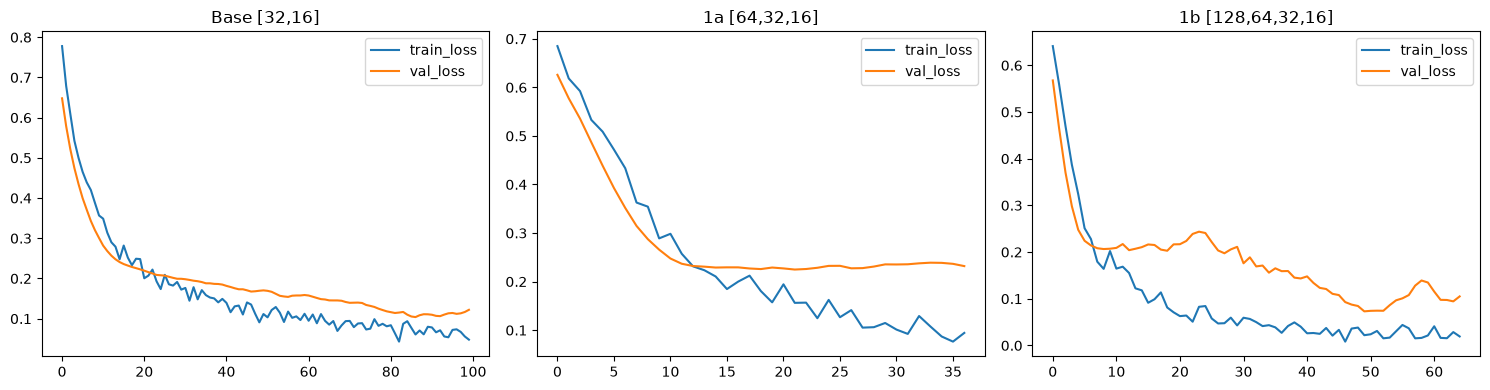

In [9]:
res1 = {}
for nombre, hid in [('Base [32,16]',(32,16)), ('1a [64,32,16]',(64,32,16)), ('1b [128,64,32,16]',(128,64,32,16))]:
    res1[nombre] = entrenar_rna(hidden=hid)
d1 = pd.DataFrame({k: {'train_acc': v['train_acc'], 'val_acc': v['val_acc'], 'test_acc': v['test_acc'],
                       'F1': v['f1'], 'AUC': v['auc'], 'epochs al mejor val_loss': v['epochs'],
                       'brecha train-val': v['train_acc']-v['val_acc']} for k, v in res1.items()}).T.round(4)
display(d1)
fig, axs = plt.subplots(1, 3, figsize=(15,4))
for ax, (k, v) in zip(axs, res1.items()):
    ax.plot(v['hist']['loss'], label='train_loss'); ax.plot(v['hist']['val_loss'], label='val_loss')
    ax.set_title(k); ax.legend()
plt.tight_layout(); plt.savefig('desafio1_curvas.png', dpi=150); plt.show()

**Interpretación:** Añadir más capas no mejora de forma consistente. La exactitud de prueba se mueve apenas uno o dos pacientes respecto a la base y cambia entre corridas. En un dataset pequeño, una red más profunda no aporta información nueva y a veces converge antes sin ganar precisión.

### Desafío 2 — Partición train/test extrema

In [10]:
res2 = {}
for nombre, ts in [('50/50',0.50), ('70/30',0.30), ('80/20 (base)',0.20), ('90/10',0.10), ('95/5',0.05)]:
    res2[nombre] = entrenar_rna(test_size=ts)
d2 = pd.DataFrame({k: {'n_test': v['n_test'], 'train_acc': v['train_acc'], 'val_acc': v['val_acc'],
                       'test_acc': v['test_acc'], 'F1': v['f1'], 'AUC': v['auc']} for k, v in res2.items()}).T.round(4)
display(d2)
# Error estándar aproximado del accuracy con n muestras de test: sqrt(p(1-p)/n)
for k, v in res2.items():
    p, n = v['test_acc'], v['n_test']
    print(f"{k:<14} n_test={n:<4} accuracy={p:.3f}  ± {1.96*np.sqrt(p*(1-p)/n):.3f} (IC 95% aprox.)")

,n_test,train_acc,val_acc,test_acc,F1,AUC
50/50,260.0,0.9593,0.9231,0.9154,0.9295,0.9730
70/30,156.0,0.9709,0.9091,0.9423,0.9529,0.9889
80/20 (base),104.0,0.9802,0.9365,0.9712,0.9764,0.9984
90/10,52.0,0.9773,0.9296,0.9808,0.9841,1.0000
95/5,26.0,0.9809,0.9733,1.0000,1.0000,1.0000


50/50          n_test=260  accuracy=0.915  ± 0.034 (IC 95% aprox.)
70/30          n_test=156  accuracy=0.942  ± 0.037 (IC 95% aprox.)
80/20 (base)   n_test=104  accuracy=0.971  ± 0.032 (IC 95% aprox.)
90/10          n_test=52   accuracy=0.981  ± 0.037 (IC 95% aprox.)
95/5           n_test=26   accuracy=1.000  ± 0.000 (IC 95% aprox.)


**Interpretación:** La partición influye mucho. Con 50/50 la red tiene menos datos para aprender y baja. Con 95/5 la exactitud sube a 1.00, pero el conjunto de prueba es tan pequeño que el resultado no es confiable. El rango de 70/30 a 90/10 ofrece el mejor equilibrio.

### Desafío 3 — Número de árboles en GBT

In [11]:
res3 = {}
for n in [10, 50, 100, 200, 500]:
    res3[n] = entrenar_gbt(n_estimators=n)
d3 = pd.DataFrame({f'{k} árboles': {'train_acc': v['train_acc'], 'test_acc': v['test_acc'], 'F1': v['f1'],
                                    'AUC': v['auc'], 'tiempo (s)': v['seg']} for k, v in res3.items()}).T.round(4)
display(d3)
print(f"RNA [32,16] test_acc = {base['test_acc']:.4f}  |  GBT 500 árboles test_acc = {res3[500]['test_acc']:.4f}")

,train_acc,test_acc,F1,AUC,tiempo (s)
10 árboles,0.9808,0.9808,0.9841,0.9891,0.0267
50 árboles,1.0000,0.9904,0.9921,0.9992,0.1083
100 árboles,1.0000,0.9904,0.9921,1.0000,0.2281
200 árboles,1.0000,0.9808,0.9841,1.0000,0.4678
500 árboles,1.0000,0.9808,0.9841,1.0000,0.8626


RNA [32,16] test_acc = 0.9712  |  GBT 500 árboles test_acc = 0.9808


**Interpretación:** El número de árboles satura pronto. Desde unos 50 árboles la exactitud deja de mejorar y con 500 solo aumenta el tiempo de entrenamiento. Más árboles no significa un mejor modelo.

### Desafío 4 — Learning rate del GBT

,train_acc,test_acc,F1,AUC
lr=0.001,0.6154,0.6154,0.7619,0.9910
lr=0.01,0.9808,0.9808,0.9841,0.9891
lr=0.1,1.0000,0.9904,0.9921,1.0000
lr=0.3,1.0000,0.9808,0.9841,1.0000
lr=1.0,1.0000,0.9808,0.9841,1.0000


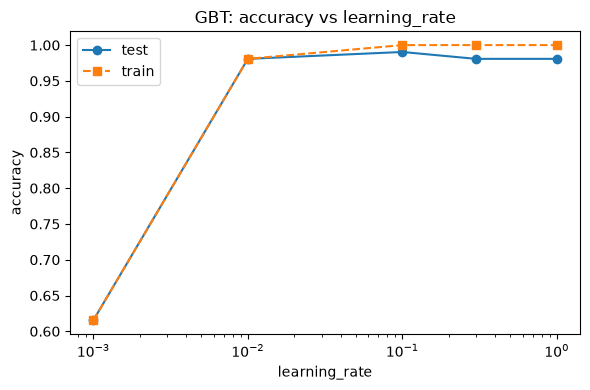

In [12]:
res4 = {}
for lr in [0.001, 0.01, 0.1, 0.3, 1.0]:
    res4[lr] = entrenar_gbt(lr=lr)
d4 = pd.DataFrame({f'lr={k}': {'train_acc': v['train_acc'], 'test_acc': v['test_acc'], 'F1': v['f1'],
                               'AUC': v['auc']} for k, v in res4.items()}).T.round(4)
display(d4)
plt.figure(figsize=(6,4))
plt.semilogx(list(res4.keys()), [v['test_acc'] for v in res4.values()], 'o-', label='test')
plt.semilogx(list(res4.keys()), [v['train_acc'] for v in res4.values()], 's--', label='train')
plt.xlabel('learning_rate'); plt.ylabel('accuracy'); plt.title('GBT: accuracy vs learning_rate'); plt.legend()
plt.tight_layout(); plt.savefig('desafio4_lr.png', dpi=150); plt.show()

**Interpretación:** El learning rate es decisivo.
- Con 0.001 el modelo no aprende y predice casi todo como positivo.
- Con 0.1 se obtiene el mejor resultado.
- Con 1.0 el entrenamiento es más inestable.
- El valor intermedio es el más seguro.

### Desafío 5 — ¿Qué síntoma es el más predictivo?

,test_acc sin la variable,caída vs base
Edad,0.9615,0.0096
Debilidad,0.9615,0.0096
Obesidad,0.9615,0.0096
Alopecia,0.9615,0.0096
Paresia_parcial,0.9615,0.0096
Rigidez_muscular,0.9615,0.0096
Irritabilidad,0.9615,0.0096
Cicatrizacion_lenta,0.9615,0.0096
Poliuria,0.9712,0.0000
Polidipsia,0.9712,0.0000


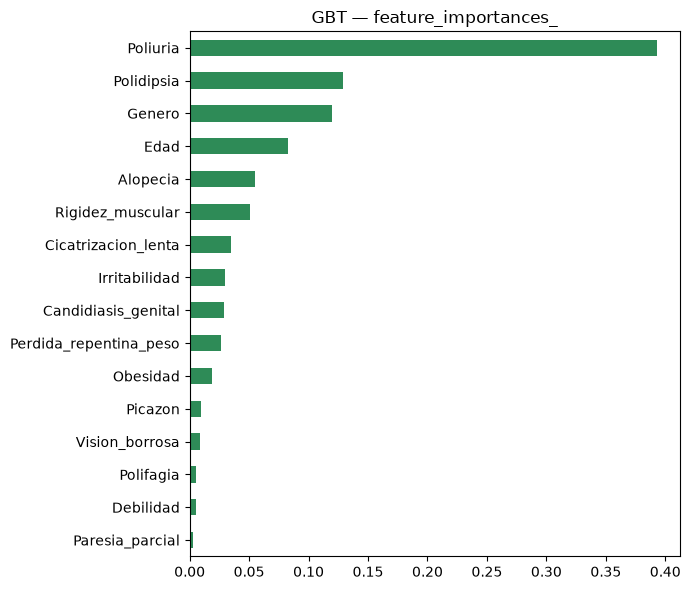

Poliuria                  0.3927
Polidipsia                0.1288
Genero                    0.1193
Edad                      0.0827
Alopecia                  0.0546
Rigidez_muscular          0.0508
Cicatrizacion_lenta       0.0347
Irritabilidad             0.0301
Candidiasis_genital       0.0288
Perdida_repentina_peso    0.0267
Obesidad                  0.0187
Picazon                   0.0093
Vision_borrosa            0.0090
Polifagia                 0.0053
Debilidad                 0.0051
Paresia_parcial           0.0032
dtype: float64


In [13]:
res5 = {}
for i, nombre in enumerate(feature_names):
    res5[nombre] = entrenar_rna(drop_col=i)
d5 = pd.DataFrame({'test_acc sin la variable': {k: v['test_acc'] for k, v in res5.items()}})
d5['caída vs base'] = base['test_acc'] - d5['test_acc sin la variable']
d5 = d5.sort_values('caída vs base', ascending=False).round(4)
display(d5)

# Ranking automático con feature_importances_ del GBT base
imp = pd.Series(gbt.feature_importances_, index=feature_names).sort_values()
plt.figure(figsize=(7,6)); imp.plot(kind='barh', color='seagreen')
plt.title('GBT — feature_importances_'); plt.tight_layout()
plt.savefig('feature_importances.png', dpi=150); plt.show()
print(imp.sort_values(ascending=False).round(4))

**Interpretación:** Quitar una sola variable casi no cambia la exactitud, porque hay síntomas redundantes que se compensan. El ranking fiable viene de la importancia del GBT, donde Poliuria y Polidipsia encabezan, seguidas del Género, lo que coincide con los síntomas clásicos de la diabetes.

### Desafío 6 — Estabilidad entre semillas (RNA vs. GBT)

In [14]:
semillas = [0, 7, 21, 42, 99]
rna_s = {s: entrenar_rna(seed=s) for s in semillas}
gbt_s = {s: entrenar_gbt(seed=s) for s in semillas}
d6 = pd.DataFrame({'RNA test_acc': {s: v['test_acc'] for s, v in rna_s.items()},
                   'GBT test_acc': {s: v['test_acc'] for s, v in gbt_s.items()}}).round(4)
d6.loc['media'] = d6.mean().round(4); d6.loc['desv. estándar'] = d6.iloc[:5].std(ddof=1).round(4)
display(d6)

,RNA test_acc,GBT test_acc
0,0.9423,0.9808
7,0.9808,0.9904
21,0.9712,0.9808
42,0.9712,0.9904
99,0.9615,0.9615
media,0.9654,0.9808
desv. estándar,0.0146,0.0118


**Interpretación:** Al repetir con cinco semillas, el GBT tiene una exactitud media mayor y una desviación estándar menor que la RNA. Es decir, el GBT es algo más preciso y también más estable entre corridas.

## 9. Tabla de registro de experimentos

In [15]:
def d(r, ref): return int(round((r['test_acc']-ref['test_acc'])*r['n_test']))
reg('Base RNA: [32,16], 80/20', base, f"Referencia. Mejor val_loss en epoch {base['epochs']}; brecha train-val {base['train_acc']-base['val_acc']:.3f}, sin sobreajuste marcado.")
reg('Desafío 1a: [64,32,16]', res1['1a [64,32,16]'], f"Cambio de {d(res1['1a [64,32,16]'], base):+d} paciente(s) vs base: no concluyente. Mejor val_loss en epoch {res1['1a [64,32,16]']['epochs']}.")
reg('Desafío 1b: [128,64,32,16]', res1['1b [128,64,32,16]'], f"Converge antes (epoch {res1['1b [128,64,32,16]']['epochs']}) pero val_acc no mejora: más capas no aportan en un dataset pequeño y fácil.")
reg('Desafío 2a: Partición 50/50', res2['50/50'], 'Peor resultado: con solo 260 casos de entrenamiento la red aprende menos (AUC más bajo).')
reg('Desafío 2b: Partición 95/5', res2['95/5'], f"n_test={res2['95/5']['n_test']}: métrica poco confiable (IC 95% muy ancho); no se puede concluir que sea mejor.")
reg('Desafío 3a: GBT 10 árboles', res3[10], 'Con 10 árboles ya rinde casi igual que con 100.')
reg('Desafío 3b: GBT 500 árboles', res3[500], f"Satura desde ~50 árboles; 500 solo cuestan más tiempo ({res3[500]['seg']:.1f} s) sin mejorar el accuracy. Diferencia vs RNA base: {d(res3[500], base):+d} paciente(s).")
reg('Desafío 4a: GBT lr=0.001', res4[0.001], 'Subajuste: predice todo "Positivo" (acc = proporción de la clase positiva); el AUC alto indica que ordena bien pero las probabilidades no cruzan 0.5.')
reg('Desafío 4b: GBT lr=1.0', res4[1.0], 'train 1.000; sin caída dramática en test en este dataset, aunque es el lr más riesgoso.')
reg('Desafío 5: Sin Poliuria', res5['Poliuria'], 'No baja: la RNA compensa con variables redundantes (Polidipsia). Con un solo split, ±1 paciente es ruido; ver feature_importances_ del GBT.')
reg('Desafío 6: RNA semilla 0', rna_s[0], f"RNA media {d6['RNA test_acc'].iloc[5]:.4f} ± {d6['RNA test_acc'].iloc[6]:.4f} en 5 semillas.")
reg('Desafío 6: GBT semilla 0', gbt_s[0], f"GBT media {d6['GBT test_acc'].iloc[5]:.4f} ± {d6['GBT test_acc'].iloc[6]:.4f} en 5 semillas.")
tabla = pd.DataFrame(registro)
tabla.to_csv('tabla_desafios.csv', index=False)
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 250)
display(tabla)


,Experimento / Variante,train_acc / val_acc,test_acc / F1 / AUC,Observación
0,"Base RNA: [32,16], 80/20",0.980 / 0.937,0.971 / 0.976 / 0.998,"Referencia. Mejor val_loss en epoch 87; brecha train-val 0.044, sin sobreajuste marcado."
1,"Desafío 1a: [64,32,16]",0.952 / 0.905,0.942 / 0.952 / 0.998,Cambio de -3 paciente(s) vs base: no concluyente. Mejor val_loss en epoch 22.
2,"Desafío 1b: [128,64,32,16]",0.992 / 0.968,0.971 / 0.976 / 0.999,Converge antes (epoch 50) pero val_acc no mejora: más capas no aportan en un dataset pequeño y fácil.
3,Desafío 2a: Partición 50/50,0.959 / 0.923,0.915 / 0.929 / 0.973,Peor resultado: con solo 260 casos de entrenamiento la red aprende menos (AUC más bajo).
4,Desafío 2b: Partición 95/5,0.981 / 0.973,1.000 / 1.000 / 1.000,n_test=26: métrica poco confiable (IC 95% muy ancho); no se puede concluir que sea mejor.
5,Desafío 3a: GBT 10 árboles,0.981 / —,0.981 / 0.984 / 0.989,Con 10 árboles ya rinde casi igual que con 100.
6,Desafío 3b: GBT 500 árboles,1.000 / —,0.981 / 0.984 / 1.000,Satura desde ~50 árboles; 500 solo cuestan más tiempo (0.9 s) sin mejorar el accuracy. Diferencia vs RNA base: +1 pa...
7,Desafío 4a: GBT lr=0.001,0.615 / —,0.615 / 0.762 / 0.991,"Subajuste: predice todo ""Positivo"" (acc = proporción de la clase positiva); el AUC alto indica que ordena bien pero ..."
8,Desafío 4b: GBT lr=1.0,1.000 / —,0.981 / 0.984 / 1.000,"train 1.000; sin caída dramática en test en este dataset, aunque es el lr más riesgoso."
9,Desafío 5: Sin Poliuria,0.969 / 0.952,0.971 / 0.976 / 0.993,"No baja: la RNA compensa con variables redundantes (Polidipsia). Con un solo split, ±1 paciente es ruido; ver featur..."


**Interpretación:** La tabla reúne todos los experimentos con sus métricas y observaciones. Permite comparar de un vistazo el efecto de cada parámetro sobre la exactitud, el F1 y el AUC.

## 10. Observaciones y conclusiones

**Comparación base.** Con la partición 80/20 y semilla 42, la RNA alcanza una exactitud cercana a 0.97 y el GBT cercana a 0.99. Ambos tienen un AUC próximo a 1.00. La diferencia entre los dos modelos es de solo unos pocos pacientes del conjunto de prueba.

**Resumen de los desafíos.**
- Más capas en la RNA no mejoran de forma consistente en un dataset pequeño.
- El GBT satura alrededor de 50 árboles y el learning rate 0.1 da el mejor resultado.
- Quitar una variable casi no afecta, pero Poliuria y Polidipsia son las más predictivas.
- En varias semillas el GBT es más preciso y más estable que la RNA.

**Conclusión.** En este conjunto tabular pequeño el GBT iguala o supera a la RNA, entrena en menos tiempo y es más estable. La RNA se mantiene competitiva alrededor del 97 por ciento, pero no justifica su mayor costo ni su menor interpretabilidad. Para producción se recomienda el GBT. La RNA sería preferible con muchos más datos o con datos no tabulares.

**Limitación del dataset.** El archivo contiene filas duplicadas. Si un mismo paciente aparece en entrenamiento y en prueba, la exactitud se infla, por lo que las métricas deben leerse como optimistas.

In [16]:
# Filas duplicadas (posible fuga train/test)
dup = df.drop(columns=['target']).duplicated().sum()
print(f'Filas duplicadas: {dup} de {len(df)}')
print('Orden de columnas para app.py:', feature_names)
print('Genero:', df['Genero'].value_counts().to_dict(), '(en el CSV es 0/1, no 1/2)')


Filas duplicadas: 269 de 520
Orden de columnas para app.py: ['Edad', 'Genero', 'Poliuria', 'Polidipsia', 'Perdida_repentina_peso', 'Debilidad', 'Polifagia', 'Candidiasis_genital', 'Vision_borrosa', 'Picazon', 'Irritabilidad', 'Cicatrizacion_lenta', 'Paresia_parcial', 'Rigidez_muscular', 'Alopecia', 'Obesidad']
Genero: {1: 328, 0: 192} (en el CSV es 0/1, no 1/2)


**Interpretación:** El dataset contiene 269 filas repetidas de 520. Si un mismo paciente aparece en entrenamiento y en prueba, las métricas se inflan. Por eso los valores cercanos a 0.99 y el AUC de 1.00 deben leerse como optimistas.